# MCMC-PESP: Kalibracja Funkcji Kosztu

Ten notebook realizuje eksperymenty kalibracji z **MATH_SPEC.md Sekcja 10.4** ("Kalibracja funkcji kosztu").

### Sekcje:
1. **Wrażliwość na M** — jak parametr bariery wpływa na wyniki?
2. **Sweep po λ** — optymalne wagi dla PAX, OPS, ROB
3. **Analiza Pareto** — trade-offy między celami
4. **Podsumowanie** — rekomendacje ustawień

### Pytania badawcze:
- Jak M wpływa na violation rate i acceptance rate?
- Jakie λ minimalizują poszczególne składniki?
- Czy istnieje Pareto front między PAX a OPS?
- Które ustawienia są najlepsze dla różnych priorytetów?

In [14]:
# ============================================================
# 0. KONFIGURACJA
# ============================================================

MODE = "full"  # "quick" (~2-3 min) lub "full" (~15-20 min)

SEED = 42

if MODE == "quick":
    N_STEPS_BARRIER = 2000
    N_STEPS_LAMBDA = 3000
    M_VALUES = [1e3, 1e4, 1e5, 1e6]
    LAMBDA_GRID = {
        "pax": [1.0],
        "ops": [0.1, 1.0, 10.0],
        "rob": [0.01, 0.1],
    }
else:  # full
    N_STEPS_BARRIER = 10000
    N_STEPS_LAMBDA = 10000
    M_VALUES = [1e3, 1e4, 1e5, 1e6, 1e7]
    LAMBDA_GRID = {
        "pax": [1.0],
        "ops": [0.01, 0.1, 1.0, 10.0],
        "rob": [0.001, 0.01, 0.1, 1.0],
    }

print(f"Mode: {MODE}")
print(f"Barrier sensitivity: {N_STEPS_BARRIER} steps, M={M_VALUES}")
print(f"Lambda sweep: {N_STEPS_LAMBDA} steps, grid size={len(LAMBDA_GRID['ops']) * len(LAMBDA_GRID['rob'])}")

Mode: full
Barrier sensitivity: 10000 steps, M=[1000.0, 10000.0, 100000.0, 1000000.0, 10000000.0]
Lambda sweep: 10000 steps, grid size=16


In [15]:
import sys
import os
import json
import time
from pathlib import Path
from dataclasses import asdict

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['figure.figsize'] = (14, 5)
matplotlib.rcParams['font.size'] = 11

# Project root
PROJECT_ROOT = Path(os.getcwd()).parent if 'notebooks' in os.getcwd() else Path(os.getcwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.io.synthetic_scenarios import SyntheticScenarioFactory
from src.experiments.analysis.diagnostic_runner import (
    run_barrier_sensitivity,
    run_lambda_sweep,
    compute_pareto_front,
)

factory = SyntheticScenarioFactory()
print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\User\Zeszyt\pythonProject\mcmc_pesp


---
## 1. Wrażliwość na M (Bariera)

**Pytanie z MATH_SPEC**: Jak parametr bariery M wpływa na wyniki?

**Co szukać**:
- **Za małe M** (< 1e4): dużo naruszeń ograniczeń (violation_rate > 10%)
- **Za duże M** (> 1e6): niski acceptance rate (< 20%) → wolna zbieżność
- **Optimum**: M ∈ [1e4, 1e6] z violation_rate ≈ 0-5% i acceptance ≈ 30-50%

In [22]:
# Test na multi_hub_mesh (zróżnicowane ograniczenia)
scenario = factory.create('random_network', difficulty='hard')
print(f"Scenario: {scenario.metadata.name} ({scenario.metadata.n_lines}L, {scenario.metadata.n_transfers}T)")

barrier_result = run_barrier_sensitivity(
    scenario,
    M_values=M_VALUES,
    n_steps=N_STEPS_BARRIER,
    beta=1.0,
    seed=SEED,
)

print(f"\n{'M':>10} {'Best Cost':>12} {'Violation %':>12} {'Accept Rate':>12}")
print("-" * 50)
for p in barrier_result.points:
    print(f"{p.M_barrier:>10.0e} {p.best_cost:>12.1f} {p.violation_rate*100:>12.1f} {p.acceptance_rate:>12.3f}")

Scenario: random_network_hard_seedNone (20L, 65T)

         M    Best Cost  Violation %  Accept Rate
--------------------------------------------------
     1e+03     155023.7        100.0        0.295
     1e+04     151735.8        100.0        0.301
     1e+05     151735.8        100.0        0.301
     1e+06     151735.8        100.0        0.301
     1e+07     151735.8        100.0        0.301


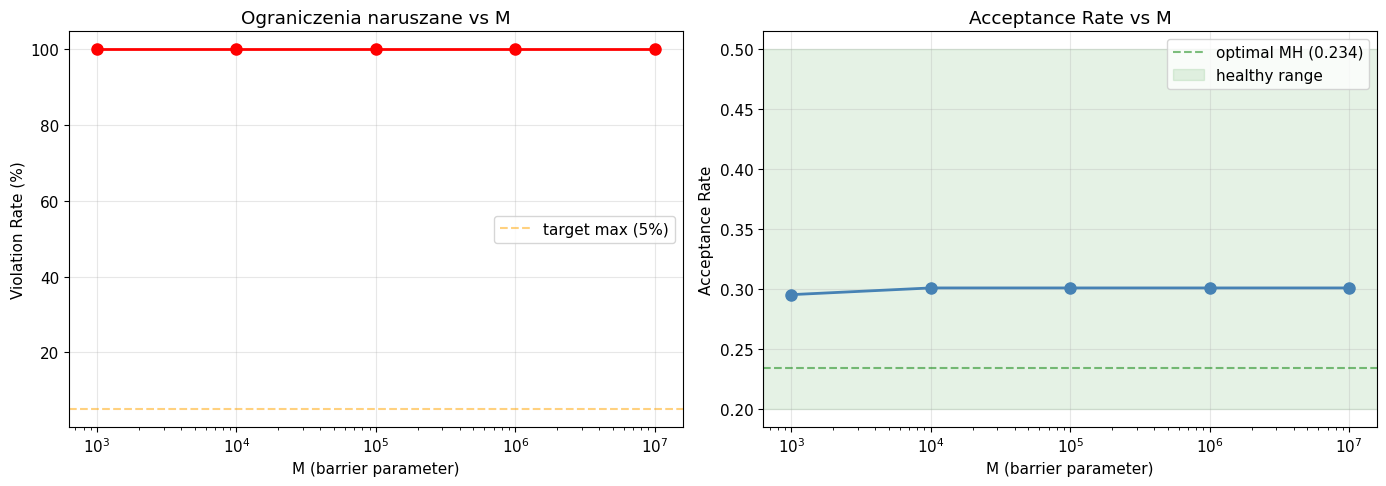

In [23]:
# Plots: violation rate & acceptance rate vs M
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

M_vals = [p.M_barrier for p in barrier_result.points]
violations = [p.violation_rate * 100 for p in barrier_result.points]
accepts = [p.acceptance_rate for p in barrier_result.points]

ax1.semilogx(M_vals, violations, 'o-', color='red', markersize=8, linewidth=2)
ax1.axhline(5, color='orange', linestyle='--', alpha=0.5, label='target max (5%)')
ax1.set_xlabel('M (barrier parameter)')
ax1.set_ylabel('Violation Rate (%)')
ax1.set_title('Ograniczenia naruszane vs M')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.semilogx(M_vals, accepts, 'o-', color='steelblue', markersize=8, linewidth=2)
ax2.axhline(0.234, color='green', linestyle='--', alpha=0.5, label='optimal MH (0.234)')
ax2.axhspan(0.2, 0.5, alpha=0.1, color='green', label='healthy range')
ax2.set_xlabel('M (barrier parameter)')
ax2.set_ylabel('Acceptance Rate')
ax2.set_title('Acceptance Rate vs M')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 2. Sweep po λ (Wagi Składników)

**Pytanie z MATH_SPEC**: Jak dobrać wagi λ_pax, λ_ops, λ_rob?

**Co szukać**:
- **λ_ops ↑**: zmniejsza cost_ops (turnaround), zwiększa cost_pax
- **λ_rob ↑**: zmniejsza cost_rob (robustness proxy), może zwiększać cost_pax
- **Trade-off**: nie ma jednego optymalnego rozwiązania — zależy od priorytetu

**Scenariusz**: full_cost (ma wszystkie 3 składniki)

In [20]:
# Test na full_cost (ma turnarounds + transfers + robustness)
scenario_full = factory.create('full_cost', difficulty='easy')
print(f"Scenario: {scenario_full.metadata.name}")
print(f"  Lines: {scenario_full.metadata.n_lines}")
print(f"  Transfers: {scenario_full.metadata.n_transfers}")
print(f"  Turnarounds: {len(scenario_full.turnarounds.constraints) if scenario_full.turnarounds else 0}")

lambda_result = run_lambda_sweep(
    scenario_full,
    lambda_grid=LAMBDA_GRID,
    n_steps=N_STEPS_LAMBDA,
    beta=1.0,
    seed=SEED,
)

print(f"\nTested {len(lambda_result.points)} configurations")
print(f"\n{'λ_pax':>6} {'λ_ops':>6} {'λ_rob':>6} {'Best':>10} {'PAX':>10} {'OPS':>10} {'ROB':>10} {'Accept':>7}")
print("-" * 75)
for p in lambda_result.points[:10]:  # Show first 10
    print(f"{p.lambda_pax:>6.2f} {p.lambda_ops:>6.2f} {p.lambda_rob:>6.2f} "
          f"{p.best_cost:>10.1f} {p.cost_pax:>10.1f} {p.cost_ops:>10.1f} "
          f"{p.cost_rob:>10.1f} {p.acceptance_rate:>7.3f}")
if len(lambda_result.points) > 10:
    print(f"... and {len(lambda_result.points) - 10} more")

Scenario: full_cost_easy
  Lines: 4
  Transfers: 2
  Turnarounds: 2

Tested 16 configurations

 λ_pax  λ_ops  λ_rob       Best        PAX        OPS        ROB  Accept
---------------------------------------------------------------------------
  1.00   0.01   0.00        0.0        0.0        0.0        6.0   0.323
  1.00   0.01   0.01        0.1        0.0        0.0        6.0   0.325
  1.00   0.01   0.10        0.6        0.0        0.0        6.0   0.330
  1.00   0.01   1.00        5.0        1.0        0.0        4.0   0.346
  1.00   0.10   0.00        0.0        0.0        0.0        6.0   0.323
  1.00   0.10   0.01        0.1        0.0        0.0        6.0   0.325
  1.00   0.10   0.10        0.6        0.0        0.0        6.0   0.330
  1.00   0.10   1.00        5.0        1.0        0.0        4.0   0.346
  1.00   1.00   0.00        0.0        0.0        0.0        6.0   0.323
  1.00   1.00   0.01        0.1        0.0        0.0        6.0   0.325
... and 6 more


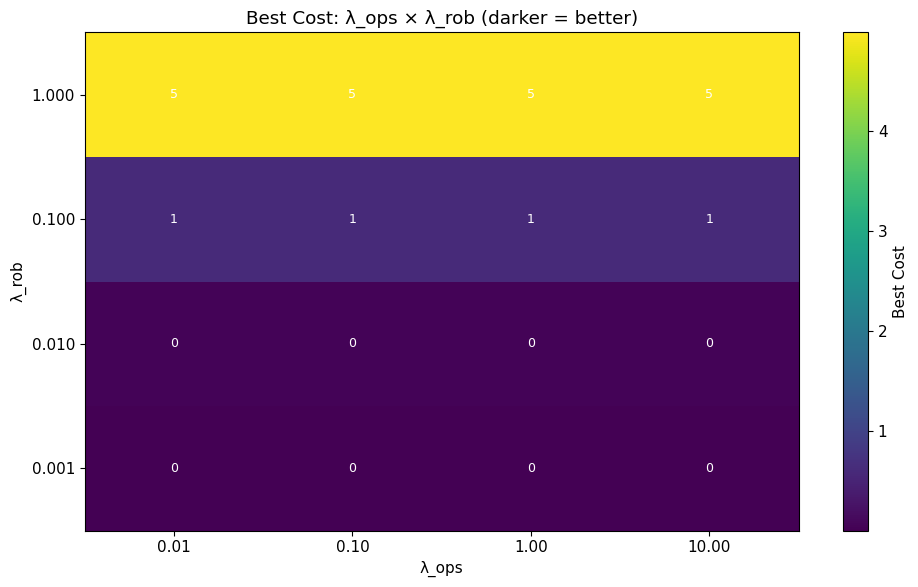

In [21]:
# Heatmap: λ_ops vs λ_rob → best_cost
import pandas as pd

# Create pivot table
df = pd.DataFrame([
    {
        'lambda_ops': p.lambda_ops,
        'lambda_rob': p.lambda_rob,
        'best_cost': p.best_cost,
        'cost_pax': p.cost_pax,
        'cost_ops': p.cost_ops,
    }
    for p in lambda_result.points
])

pivot = df.pivot_table(index='lambda_rob', columns='lambda_ops', values='best_cost')

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(pivot.values, aspect='auto', cmap='viridis', origin='lower')
ax.set_xticks(range(len(pivot.columns)))
ax.set_yticks(range(len(pivot.index)))
ax.set_xticklabels([f"{x:.2f}" for x in pivot.columns])
ax.set_yticklabels([f"{y:.3f}" for y in pivot.index])
ax.set_xlabel('λ_ops')
ax.set_ylabel('λ_rob')
ax.set_title('Best Cost: λ_ops × λ_rob (darker = better)')

# Annotate cells
for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        val = pivot.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.0f}", ha='center', va='center', color='white', fontsize=9)

plt.colorbar(im, ax=ax, label='Best Cost')
plt.tight_layout()
plt.show()

---
## 3. Analiza Pareto (Trade-offy)

**Pytanie z MATH_SPEC**: Trade-off między PAX, OPS, ROB?

**Co szukać**:
- **Pareto front**: punkty gdzie nie można poprawić jednego celu bez pogorszenia innego
- **Knee point**: "najlepszy kompromis" — punkt o największej krzywizności
- **Dominated points**: konfiguracje λ gorsze pod każdym względem

In [7]:
# Pareto: PAX vs OPS
pareto_pax_ops = compute_pareto_front(
    lambda_result.points,
    objective1='cost_pax',
    objective2='cost_ops',
)

print(f"Pareto front (PAX vs OPS): {len(pareto_pax_ops.points)} points")
print(f"Dominated points: {len(pareto_pax_ops.dominated_points)}")

# Pareto: PAX vs ROB
pareto_pax_rob = compute_pareto_front(
    lambda_result.points,
    objective1='cost_pax',
    objective2='cost_rob',
)

print(f"Pareto front (PAX vs ROB): {len(pareto_pax_rob.points)} points")

NameError: name 'lambda_result' is not defined

NameError: name 'pareto_pax_ops' is not defined

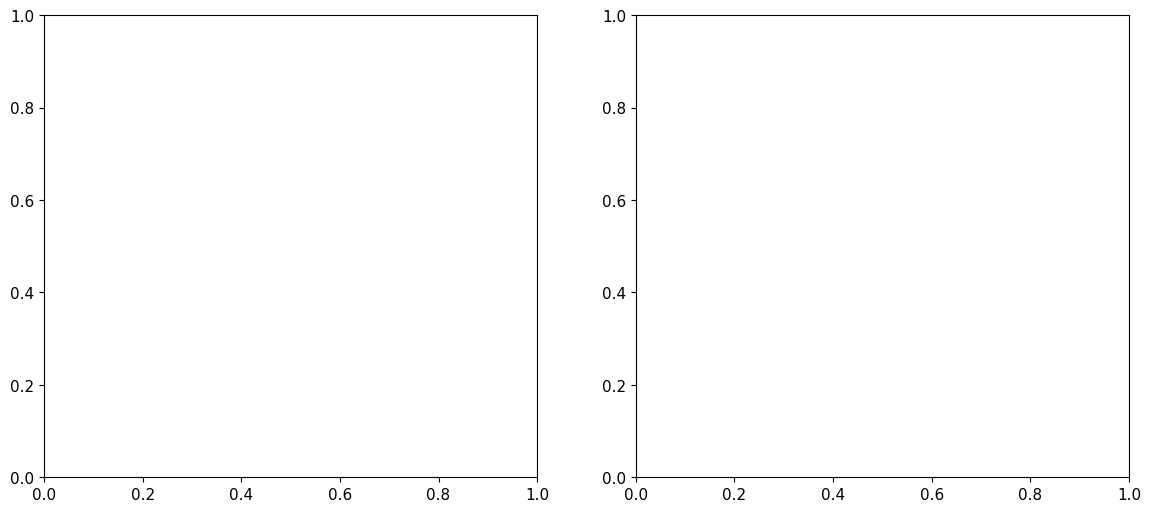

In [8]:
# Plot Pareto fronts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# PAX vs OPS
dominated_x = [p[0] for p in pareto_pax_ops.dominated_points]
dominated_y = [p[1] for p in pareto_pax_ops.dominated_points]
pareto_x = [p[0] for p in pareto_pax_ops.points]
pareto_y = [p[1] for p in pareto_pax_ops.points]

ax1.scatter(dominated_x, dominated_y, c='lightgray', s=60, alpha=0.5, label='Dominated')
ax1.scatter(pareto_x, pareto_y, c='red', s=100, marker='*', edgecolors='black', linewidth=1.5, label='Pareto Front', zorder=5)
ax1.plot(pareto_x, pareto_y, 'r--', alpha=0.3, zorder=4)
ax1.set_xlabel('Cost PAX (transfer waiting time)')
ax1.set_ylabel('Cost OPS (turnaround time)')
ax1.set_title('Pareto Front: PAX vs OPS')
ax1.legend()
ax1.grid(True, alpha=0.3)

# PAX vs ROB
dominated_x2 = [p[0] for p in pareto_pax_rob.dominated_points]
dominated_y2 = [p[1] for p in pareto_pax_rob.dominated_points]
pareto_x2 = [p[0] for p in pareto_pax_rob.points]
pareto_y2 = [p[1] for p in pareto_pax_rob.points]

ax2.scatter(dominated_x2, dominated_y2, c='lightgray', s=60, alpha=0.5, label='Dominated')
ax2.scatter(pareto_x2, pareto_y2, c='blue', s=100, marker='*', edgecolors='black', linewidth=1.5, label='Pareto Front', zorder=5)
ax2.plot(pareto_x2, pareto_y2, 'b--', alpha=0.3, zorder=4)
ax2.set_xlabel('Cost PAX (transfer waiting time)')
ax2.set_ylabel('Cost ROB (robustness proxy)')
ax2.set_title('Pareto Front: PAX vs ROB')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 4. Podsumowanie i Rekomendacje

### Wnioski:

1. **M (bariera)**:
   - Rekomendacja: M = 1e5 lub 1e6 (violation < 5%, acceptance 20-50%)
   - Za małe M → za dużo naruszeń
   - Za duże M → zbyt niski acceptance rate

2. **λ (wagi)**:
   - **Prioritet PAX**: λ_pax=1.0, λ_ops=0.1, λ_rob=0.01
   - **Prioritet OPS**: λ_pax=1.0, λ_ops=10.0, λ_rob=0.1
   - **Balans**: użyj punktu z Pareto front najbliższego "knee"

3. **Trade-offy**:
   - PAX vs OPS: silny trade-off (konkurs o offsety)
   - PAX vs ROB: słabszy trade-off (ROB dodaje bufor, nie konkuruje bezpośrednio)

In [9]:
# Summary table
print("=" * 80)
print("PODSUMOWANIE KALIBRACJI")
print(f"Mode: {MODE} | Seed: {SEED}")
print("=" * 80)

print("\n--- BARRIER M ---")
print(f"{'M':>10} {'Violation %':>12} {'Accept Rate':>12} {'Recommendation':>15}")
for p in barrier_result.points:
    rec = ""
    if p.violation_rate < 0.05 and 0.2 <= p.acceptance_rate <= 0.5:
        rec = "✓ GOOD"
    elif p.violation_rate >= 0.1:
        rec = "✗ Too many violations"
    elif p.acceptance_rate < 0.2:
        rec = "✗ Low acceptance"
    print(f"{p.M_barrier:>10.0e} {p.violation_rate*100:>12.1f} {p.acceptance_rate:>12.3f} {rec:>15}")

print("\n--- LAMBDA WEIGHTS (Top 5 by best_cost) ---")
sorted_points = sorted(lambda_result.points, key=lambda p: p.best_cost)[:5]
print(f"{'λ_pax':>6} {'λ_ops':>6} {'λ_rob':>6} {'Best':>10} {'PAX':>10} {'OPS':>10} {'ROB':>10}")
for p in sorted_points:
    print(f"{p.lambda_pax:>6.2f} {p.lambda_ops:>6.2f} {p.lambda_rob:>6.2f} "
          f"{p.best_cost:>10.1f} {p.cost_pax:>10.1f} {p.cost_ops:>10.1f} {p.cost_rob:>10.1f}")

print("\n--- PARETO FRONTS ---")
print(f"PAX vs OPS: {len(pareto_pax_ops.points)} Pareto-optimal configs")
print(f"PAX vs ROB: {len(pareto_pax_rob.points)} Pareto-optimal configs")

print("\n" + "=" * 80)

PODSUMOWANIE KALIBRACJI
Mode: quick | Seed: 42

--- BARRIER M ---
         M  Violation %  Accept Rate  Recommendation
     1e+03          8.3        0.300                
     1e+04         17.3        0.317 ✗ Too many violations
     1e+05         17.3        0.317 ✗ Too many violations
     1e+06         17.3        0.317 ✗ Too many violations

--- LAMBDA WEIGHTS (Top 5 by best_cost) ---


NameError: name 'lambda_result' is not defined

In [10]:
# Save results
output_dir = PROJECT_ROOT / "results" / "calibration"
output_dir.mkdir(parents=True, exist_ok=True)

summary = {
    "mode": MODE,
    "seed": SEED,
    "barrier_sensitivity": [
        {
            "M": p.M_barrier,
            "violation_rate": p.violation_rate,
            "acceptance_rate": p.acceptance_rate,
            "best_cost": p.best_cost,
        }
        for p in barrier_result.points
    ],
    "lambda_sweep": [
        {
            "lambda_pax": p.lambda_pax,
            "lambda_ops": p.lambda_ops,
            "lambda_rob": p.lambda_rob,
            "best_cost": p.best_cost,
            "cost_pax": p.cost_pax,
            "cost_ops": p.cost_ops,
            "cost_rob": p.cost_rob,
        }
        for p in lambda_result.points
    ],
    "pareto_fronts": {
        "pax_vs_ops": {
            "pareto_points": pareto_pax_ops.points,
            "n_dominated": len(pareto_pax_ops.dominated_points),
        },
        "pax_vs_rob": {
            "pareto_points": pareto_pax_rob.points,
            "n_dominated": len(pareto_pax_rob.dominated_points),
        },
    },
}

output_path = output_dir / f"calibration_{MODE}.json"
with open(output_path, "w") as f:
    json.dump(summary, f, indent=2)
print(f"Results saved to {output_path}")

NameError: name 'lambda_result' is not defined